In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from src.utils.config import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

# 04 Churn prediction
Training code: `src/models/train.py`. Features exclude CLV, churn fields, cancellation fields and gender (see tests/test_pipeline.py).

In [2]:
rep = json.load(open(REPORTS/'model_report.json'))
display(pd.DataFrame(rep['churn_comparison']).round(3))
print(rep['churn_selection_rule'])

,model,cv_auc_mean,cv_auc_std,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.662,0.019,0.656,0.366,0.520,0.430,0.651,0.385
1,XGBoost,0.661,0.014,0.624,0.349,0.593,0.440,0.652,0.401
2,Gradient Boosting,0.659,0.016,0.755,0.546,0.090,0.155,0.658,0.408
3,Logistic Regression,0.658,0.015,0.615,0.344,0.606,0.439,0.655,0.389


best CV AUC = Random Forest (0.6623 +/- 0.0191); XGBoost within 1 std -> chosen for explainability


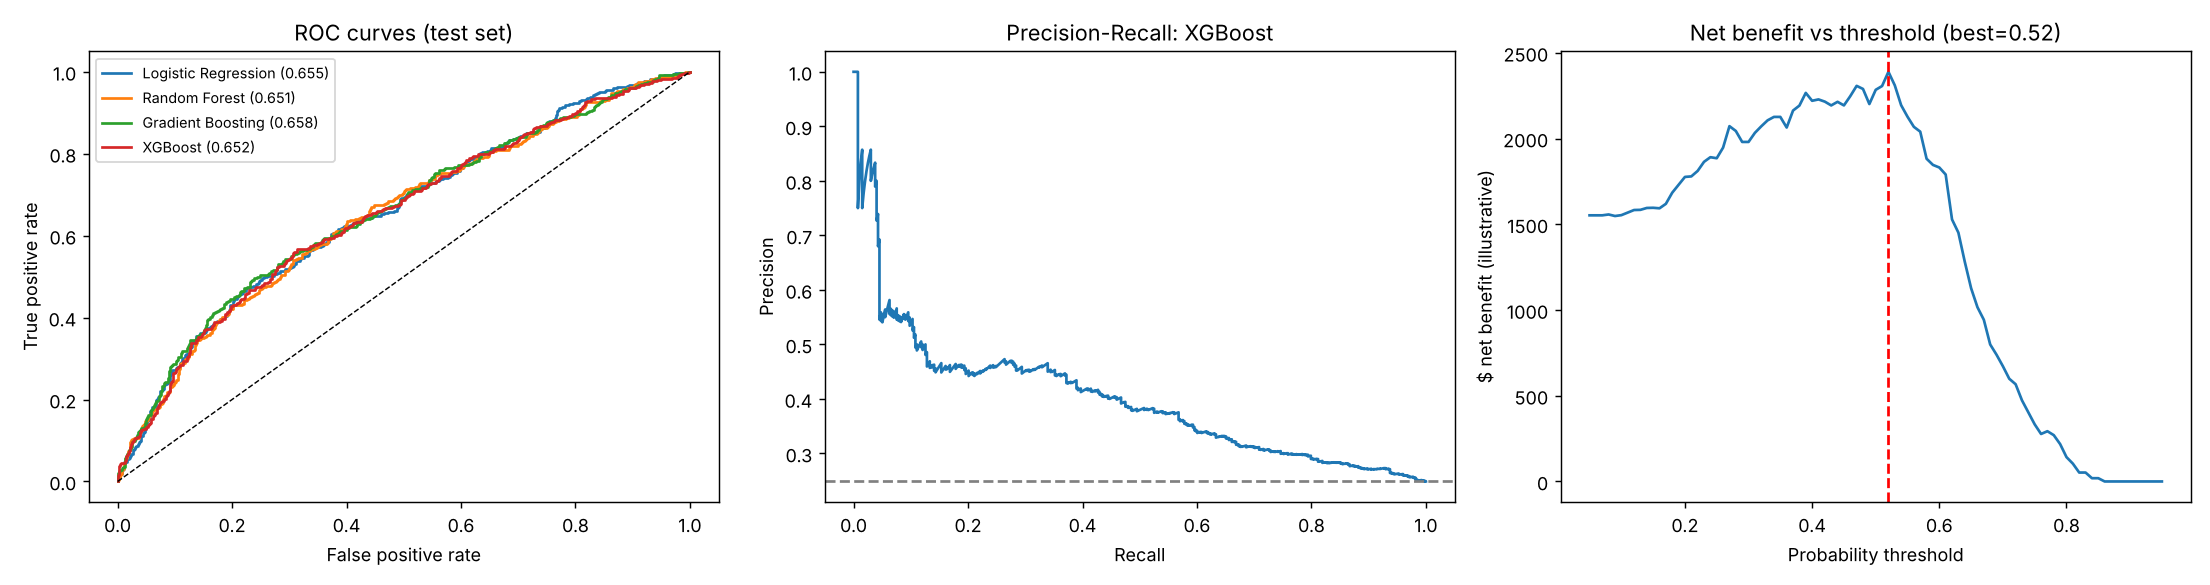

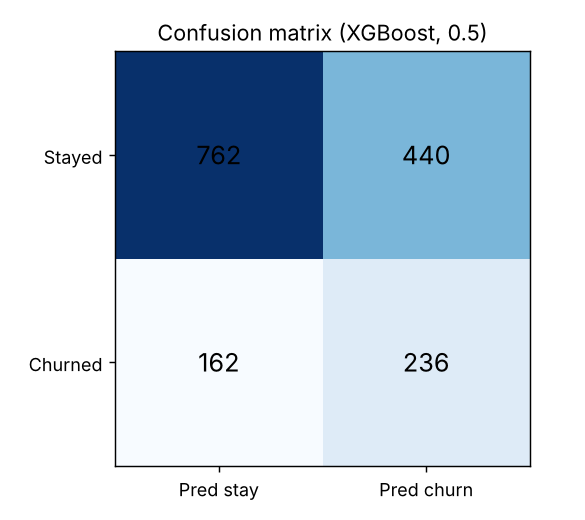

In [3]:
display(Image(filename=str(FIGURES/'model_churn_curves.png'))); display(Image(filename=str(FIGURES/'model_churn_confusion.png'), width=380))

In [4]:
print(json.dumps(rep['churn_thresholds'], indent=1)); print(rep['churn_decile_lift']); print(rep['risk_tier_counts'], rep['risk_tier_churn_rates'])

{
 "default_0.5": {
  "accuracy": 0.62375,
  "precision": 0.34911242603550297,
  "recall": 0.592964824120603,
  "f1": 0.43947858472998136,
  "roc_auc": 0.6523925785332653,
  "pr_auc": 0.40066449853708586
 },
 "profit_optimal": {
  "threshold": 0.5199999999999999,
  "accuracy": 0.654375,
  "precision": 0.3723228995057661,
  "recall": 0.5678391959798995,
  "f1": 0.44975124378109455,
  "roc_auc": 0.6523925785332653,
  "pr_auc": 0.40066449853708586
 },
 "assumptions": {
  "cost_per_offer": 5.0,
  "value_per_saved_churner": 24.0
 }
}
{'base_rate': 0.248875, 'top_decile_churn_rate': 0.44875, 'bottom_decile_churn_rate': 0.085, 'top_decile_lift': 1.8031140130587642}
{'Low': 3519, 'Medium': 3234, 'High': 1247} {'High': 0.443, 'Low': 0.15, 'Medium': 0.282}


## Model choice (written justification)
**All four candidates are statistically tied** (CV ROC-AUC 0.658-0.662, fold std 0.014-0.019). Picking 'the winner' by the 4th decimal would be fooling ourselves. XGBoost was chosen because it is within one standard deviation of the best and gives exact per-customer TreeSHAP explanations, so the score and its explanation come from the same model.

**Precision/recall in a retention-offer context.** A wasted offer costs money (assumed $5); a missed churner costs the revenue we could have kept (assumed ~$24 expected: 30% accept x ~$80 retained). Contacting a customer pays off when P(churn) > 5/24 = 21%. That is why the tiers are Low < 21%, Medium 21-40%, High >= 40%, and why the profit-optimal threshold favours **recall (~57%) over precision (~37%)** (at the default 0.5 cut-off the XGBoost figures are recall 59%, precision 35%): it is cheap to be wrong about who to offer, expensive to miss them. **These dollar figures are my assumptions, not your data. Change them in `src/models/train.py`.**

**What the model can and cannot do.** ROC-AUC 0.65 is weak. It is useful for *ranking* (top decile churns 45% vs 25% base, bottom decile 8.5%) and poor for calling any single person. Probabilities are isotonic-calibrated on out-of-fold scores.

In [5]:
import joblib, xgboost as xgb
from src.models.train import CAT, CHURN_NUM
b = joblib.load(MODELS/'churn_xgb_explainer.joblib'); pipe = b['model']
f = pd.read_csv(PROCESSED/'customer_features.csv').sample(1500, random_state=1)
Xt = pipe.named_steps['pre'].transform(f[CAT+CHURN_NUM]); names = [n.split('__',1)[1] for n in pipe.named_steps['pre'].get_feature_names_out()]
c = pipe.named_steps['m'].get_booster().predict(xgb.DMatrix(Xt), pred_contribs=True)[:, :-1]
pd.Series(np.abs(c).mean(0), index=names).sort_values(ascending=False).head(15).round(3)

customer_tenure_days         0.189
monthly_watch_time_trend     0.182
watch_min_last_3m            0.178
avg_customer_satisfaction    0.156
failed_payment_rate          0.120
days_since_last_activity     0.103
failed_payment_count         0.081
total_watch_minutes          0.060
auto_renew                   0.057
support_ticket_count         0.055
engagement_score             0.052
watch_trend_log_ratio        0.046
avg_completion_pct           0.045
watch_min_prev_3m            0.039
total_sessions               0.034
dtype: float32